# Performing a Simple Linear Regression

*Section 5 — Regression, notebook 3 of 6.* Previous: `02_feature_selection`. Next: `04_multiple_linear_regression`.

**You will learn:**

- how to fit a simple linear regression (y = ax + b) with scikit-learn;
- how to assess it on a test set with `rsgispy.regression.regmetrics.calc_reg_metrics` and check the residuals with `plot_residuals`;
- how to apply the model to the LiDAR metrics image with `rsgispy.imagecalc.maths.band_maths`;
- how to map the three results side by side, with colour bars, with `rsgispy.mapping.layout.create_map_panels`.

**Before you start:** notebook 1, where the predictors used here were chosen from the correlation tables. Nothing from earlier notebooks needs to have been run.

**Data:** `../data/lidar/Forest_Plot_Metrics.csv`, `../data/lidar/Forest_ALS_Metrics.tif` and `../data/lidar/Forest_ALS_Valid.tif`.

**Run time:** about 1 minute.

## The model

While we know that a more complex model is probably required, let’s start with testing using just a simple model, using a single input variable where our model will be in the form:


$$
  y = ax + b
$$


The analysis will need to be performed independently for each of the dependent variables, which we will select using the correlation tables (i.e., the independent variable with the highest correlation to the dependent variable):


| Dependant Variable | Independent (Predictor) Variable |
| ------------------ | -------------------------------- |
| Vol / ha           | chm_vf                           |
| BA / ha            | chm_vf                           |
| Mean DBH           | h90                              |

# 1. Imports

In [1]:
import os

import matplotlib.pyplot as plt
import numpy
import pandas
import rsgispy
import sklearn.linear_model
import sklearn.model_selection
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imageutils.metadata import get_band_names
from rsgispy.imageutils.stats import pop_img_stats
from rsgispy.mapping.layout import MapPanel, create_map_panels
from rsgispy.regression.regmetrics import calc_reg_metrics, plot_residuals

In [2]:
%matplotlib inline

# 2. Read the input plot data 

In [3]:
# Open the CSV file as a Pandas data frame - the df variable.
df = pandas.read_csv("../data/lidar/Forest_Plot_Metrics.csv")

# All the files created by this notebook are written to the outputs directory.
out_dir = os.path.join("outputs", "simple_linear_out_imgs")
os.makedirs(out_dir, exist_ok=True)

## 2.1 Summarising the test accuracy

`rsgispy.regression.regmetrics.calc_reg_metrics` calculates the accuracy metrics from a table with the observed (reference) and predicted values: the coefficient of determination (r2), the root mean squared error (rmse), the mean absolute error (mae), the bias (mean of predicted - observed), the explained variance, the Pearson correlation (pearson_r), the mean squared error (mse), and the RMSE and bias as a percentage of the mean observed value (nrmse and nbias, %) and the RMSE as a percentage of the observed range (nrmse_range, %). The test values are put in a small DataFrame with an observed (`obs`) and a predicted (`pred`) column.

> **RSGISLib users:** `rsgislib.regression.get_regression_stats(y_test, y_pred, n_vars=1)` returned a list with a dict for each variable; `calc_reg_metrics` returns one dict (with per-target keys for multiple targets) and takes a DataFrame, vector layer or table file.

# 3. Fitting a Simple Linear Regression

Using the scikit-learn library the following scripts fit simple linear relationships for the three dependent variables

## 3.1 Vol / ha

In [4]:
# Get the chm_vf predictor variable and 'Vol / ha' dependent variable
# from the dataframe as numpy arrays
x = df[["chm_vf"]].values
y = df["Vol / ha"].values

# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Create a LinearRegression object
lm = sklearn.linear_model.LinearRegression()

# Fit the model using the training data
vol_mdl = lm.fit(x_train, y_train)

# Print the equation of the model
print("y = ax + b")
print("vol = ({} * chm_vf) + {}".format(vol_mdl.coef_[0], vol_mdl.intercept_))

y = ax + b
vol = (0.071875325856536 * chm_vf) + -58.027587035109036


In [5]:
# A dict for the observed and predicted test values of each model.
test_dfs = dict()

# Predict the values using the model for the test data and calculate the accuracy metrics.
y_pred = vol_mdl.predict(x_test)
test_df = pandas.DataFrame({"obs": y_test, "pred": y_pred})
regress_vol_stats = calc_reg_metrics(test_df, ref_col="obs", pred_col="pred")
# Keep the test values for the residual plots in section 4.
test_dfs["vol"] = test_df
regress_vol_stats

{'r2': 0.9186646095070512,
 'rmse': 67.85702625982853,
 'mae': 46.83664611350415,
 'bias': -19.772692979977943,
 'explained_variance': 0.9255705296993322,
 'pearson_r': 0.9651798837868608,
 'mse': 4604.576012827059,
 'nrmse': 23.295021131201228,
 'nrmse_range': 9.011557272221584,
 'nbias': -6.7878792540312,
 'n_samples': 34}

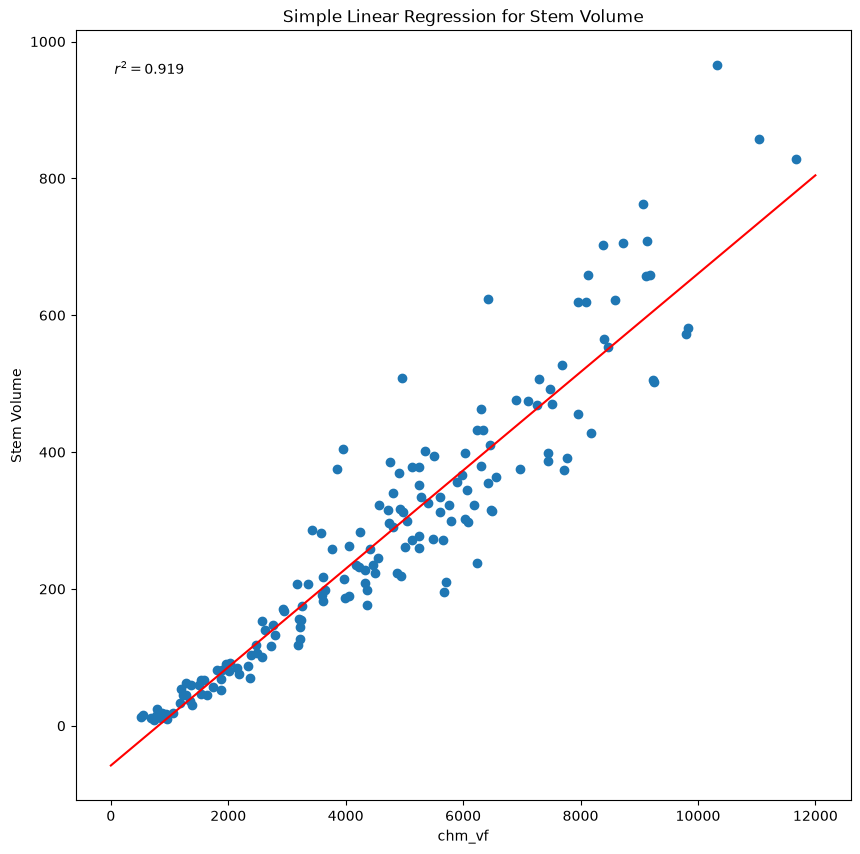

In [6]:
# Create 100 values at regular intervals between 0 and 12000
# to plot the relationship
x_plot = numpy.expand_dims(numpy.linspace(0, 12000, 100), axis=1)
# Calculate the values
y_plot = vol_mdl.predict(x_plot)

# Plot the relationship
fig = plt.figure(figsize=(10, 10))
ax1 = fig.add_subplot(111)
plt.scatter(x, y)
plt.plot(x_plot, y_plot, color="red")
rSqStr = "$r^2 = " + str(round(regress_vol_stats["r2"], 3)) + "$"
plt.text(0.05, 0.95, rSqStr, va="center", transform=ax1.transAxes)
plt.title("Simple Linear Regression for Stem Volume")
plt.xlabel("chm_vf")
plt.ylabel("Stem Volume")
plt.show()

## 3.2 BA / ha

In [7]:
# Get the chm_vf predictor variable and 'BA / ha' dependent variable
# from the dataframe as numpy arrays
x = df[["chm_vf"]].values
y = df["BA / ha"].values

# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Create a LinearRegression object
lm = sklearn.linear_model.LinearRegression()

# Fit the model using the training data
ba_mdl = lm.fit(x_train, y_train)

# Print the equation of the model
print("y = ax + b")
print("ba = ({} * chm_vf) + {}".format(ba_mdl.coef_[0], ba_mdl.intercept_))

y = ax + b
ba = (0.0063541469301120306 * chm_vf) + 6.277088802823478


In [8]:
# Predict the values using the model for the test data and calculate the accuracy metrics.
y_pred = ba_mdl.predict(x_test)
test_df = pandas.DataFrame({"obs": y_test, "pred": y_pred})
regress_ba_stats = calc_reg_metrics(test_df, ref_col="obs", pred_col="pred")
# Keep the test values for the residual plots in section 4.
test_dfs["ba"] = test_df
regress_ba_stats

{'r2': 0.8546330240635285,
 'rmse': 8.641153301923787,
 'mae': 6.980170727431494,
 'bias': -0.11997306200501612,
 'explained_variance': 0.8546610454630652,
 'pearson_r': 0.930620418854644,
 'mse': 74.66953038734836,
 'nrmse': 24.320120215670606,
 'nrmse_range': 11.442205113776199,
 'nbias': -0.3376585495774635,
 'n_samples': 34}

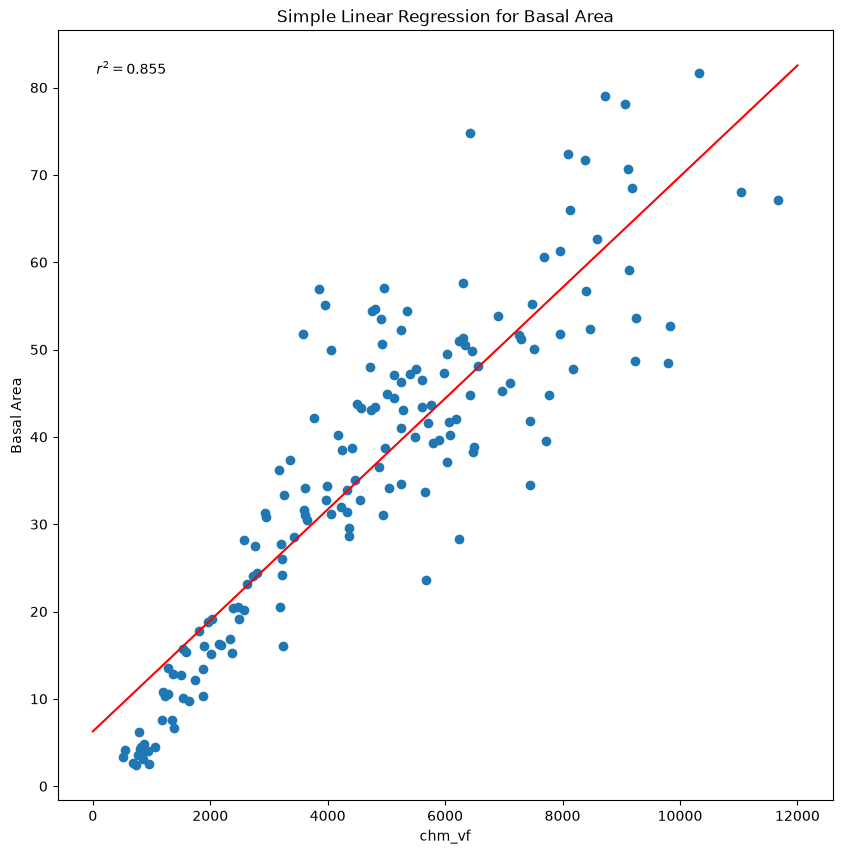

In [9]:
# Create 100 values at regular intervals between 0 and 12000
# to plot the relationship
x_plot = numpy.expand_dims(numpy.linspace(0, 12000, 100), axis=1)
# Calculate the values
y_plot = ba_mdl.predict(x_plot)

# Plot the relationship
fig = plt.figure(figsize=(10, 10))
ax1 = fig.add_subplot(111)
plt.scatter(x, y)
plt.plot(x_plot, y_plot, color="red")
rSqStr = "$r^2 = " + str(round(regress_ba_stats["r2"], 3)) + "$"
plt.text(0.05, 0.95, rSqStr, va="center", transform=ax1.transAxes)
plt.title("Simple Linear Regression for Basal Area")
plt.xlabel("chm_vf")
plt.ylabel("Basal Area")
plt.show()

## 3.3 Mean DBH

In [10]:
# Get the h90 predictor variable and 'Mean DBH' dependent variable
# from the dataframe as numpy arrays
x = df[["h90"]].values
y = df["Mean DBH"].values

# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Create a LinearRegression object
lm = sklearn.linear_model.LinearRegression()

# Fit the model using the training data
dbh_mdl = lm.fit(x_train, y_train)

# Print the equation of the model
print("y = ax + b")
print("dbh = ({} * h90) + {}".format(dbh_mdl.coef_[0], dbh_mdl.intercept_))

y = ax + b
dbh = (1.1045861431975346 * h90) + 3.998609786869636


In [11]:
# Predict the values using the model for the test data and calculate the accuracy metrics.
y_pred = dbh_mdl.predict(x_test)
test_df = pandas.DataFrame({"obs": y_test, "pred": y_pred})
regress_dbh_stats = calc_reg_metrics(test_df, ref_col="obs", pred_col="pred")
# Keep the test values for the residual plots in section 4.
test_dfs["dbh"] = test_df
regress_dbh_stats

{'r2': 0.8924495708781768,
 'rmse': 2.374236892530539,
 'mae': 1.586913447537509,
 'bias': -0.22701760268100024,
 'explained_variance': 0.8934328642592797,
 'pearson_r': 0.9455256490155961,
 'mse': 5.637000821853071,
 'nrmse': 13.658892444338127,
 'nrmse_range': 7.9141229751017965,
 'nbias': -1.3060234333593923,
 'n_samples': 34}

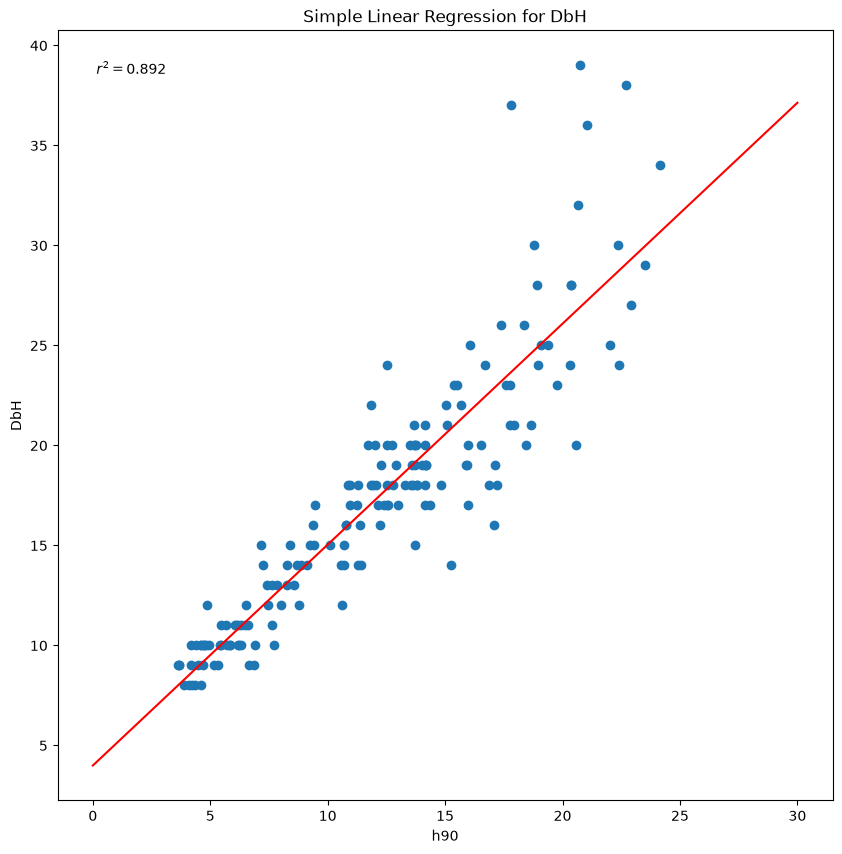

In [12]:
# Create 100 values at regular intervals between 0 and 30
# to plot the relationship
x_plot = numpy.expand_dims(numpy.linspace(0, 30, 100), axis=1)
# Calculate the values
y_plot = dbh_mdl.predict(x_plot)

# Plot the relationship
fig = plt.figure(figsize=(10, 10))
ax1 = fig.add_subplot(111)
plt.scatter(x, y)
plt.plot(x_plot, y_plot, color="red")
rSqStr = "$r^2 = " + str(round(regress_dbh_stats["r2"], 3)) + "$"
plt.text(0.05, 0.95, rSqStr, va="center", transform=ax1.transAxes)
plt.title("Simple Linear Regression for DbH")
plt.xlabel("h90")
plt.ylabel("DbH")
plt.show()

# 4. Summarising Results

Within the code above you will see that the data is split to create testing and training datasets, as you would with a classification problem. The testing data can then be used to estimate the accuracy of the model developed, summarised in the table below (created by the next cell):

| Dependant Variable | R2    | MAE  | MSE    | RMSE  | %RMSE  |
| ------------------ | ----- | ---- | ------ | ----- | ------ |
| Vol / ha           | 0.919 | 46.8 | 4604.6 | 67.9  | 23.3 % |
| BA / ha            | 0.855 | 7.0  | 74.7   | 8.6   | 24.3 % |
| Mean DBH           | 0.892 | 1.6  | 5.6    | 2.4   | 13.7 % |

We also have the equations to predict the dependant variables, which we can now use apply the relationship to the image data:

| Dependant Variable | a      | b      |
| ------------------ | ------ | ------ |
| Vol / ha           | 0.0719 | -58.03 |
| BA / ha            | 0.0064 | 6.28   |
| Mean DBH           | 1.1046 | 4.00   |

*Note. these coefficients and summary statistics might be a little different from what you have depending on the version of scikit-learn and random selection of the training and testing datasets*

In [13]:
# Summarise the test accuracy and the fitted coefficients of the three models.
summary = pandas.DataFrame(
    {
        "R2": [s["r2"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
        "MAE": [s["mae"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
        "MSE": [s["mse"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
        "RMSE": [s["rmse"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
        "%RMSE": [s["nrmse"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
        "a": [m.coef_[0] for m in (vol_mdl, ba_mdl, dbh_mdl)],
        "b": [m.intercept_ for m in (vol_mdl, ba_mdl, dbh_mdl)],
    },
    index=["Vol / ha", "BA / ha", "Mean DBH"],
)
summary.round(4)

,R2,MAE,MSE,RMSE,%RMSE,a,b
Vol / ha,0.9187,46.8366,4604.5760,67.8570,23.2950,0.0719,-58.0276
BA / ha,0.8546,6.9802,74.6695,8.6412,24.3201,0.0064,6.2771
Mean DBH,0.8924,1.5869,5.6370,2.3742,13.6589,1.1046,3.9986


## 4.1 Residuals

The residuals (predicted - observed) of the test plots show whether the errors of a model are unbiased and have a similar spread over the range of predicted values (homoscedasticity, one of the regression assumptions in notebook 1). `plot_residuals` from `rsgispy.regression.regmetrics` plots the residuals against the predicted values, with a histogram of the residuals beside them (and the normal curve with the same mean and standard deviation), for one or more variables:

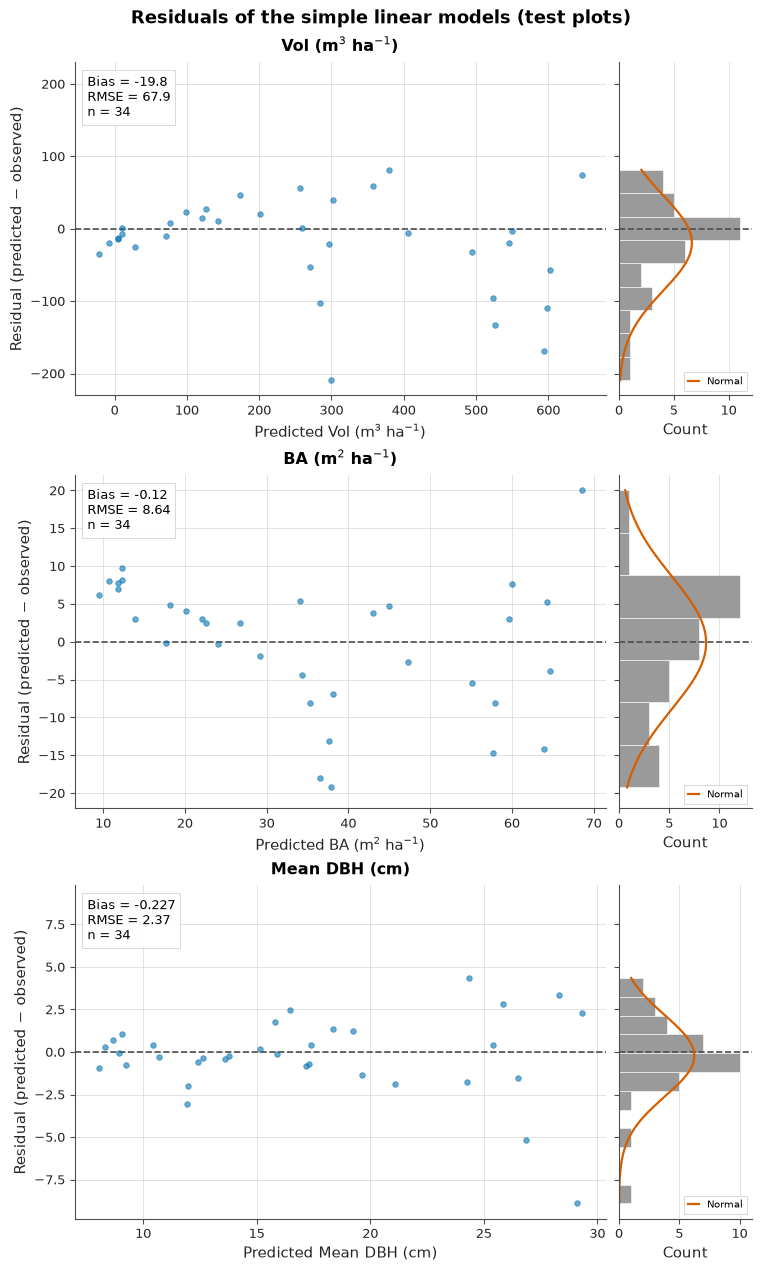

In [14]:
# Join the observed and predicted test values of the three models into one
# table, with an observed and a predicted column for each variable.
resid_df = pandas.concat(
    [test_dfs[var].add_suffix("_{}".format(var)) for var in ["vol", "ba", "dbh"]], axis=1
)
fig, axs = plot_residuals(
    resid_df,
    ref_cols=["obs_vol", "obs_ba", "obs_dbh"],
    pred_cols=["pred_vol", "pred_ba", "pred_dbh"],
    target_names=["Vol (m$^3$ ha$^{-1}$)", "BA (m$^2$ ha$^{-1}$)", "Mean DBH (cm)"],
    title="Residuals of the simple linear models (test plots)",
)

With only 34 test plots the residuals are noisy, but two patterns are clear. First, the spread of the residuals grows with the predicted value for all three variables (a funnel shape): this is the heteroscedasticity we saw in the scatter plots in notebook 1. Second, the residuals are not centred on zero over the whole range: the volume model overestimates most plots with predicted volumes of 100-400 m$^3$ ha$^{-1}$ (positive residuals) and underestimates most of those above 450 m$^3$ ha$^{-1}$ (large negative residuals), and the basal area model overestimates all the plots with predicted values below 25 m$^2$ ha$^{-1}$, so the relationships are not quite straight lines. The negative bias of the volume model (-19.8 m$^3$ ha$^{-1}$) comes mostly from those few large plots.

# 5. Applying our Model to the Image Data

Now we have the equations for the relationships we can apply these to the image data to get a spatial prediction of the variables. Here the `band_maths` expressions are written by hand from the coefficients; notebook 4 builds them from the fitted model with `rsgispy.regression.regsklearn.get_linear_model_band_maths_exp`.


## 5.1 Create output directory

In [15]:
# The output images are written to out_dir, which was created in section 2.
print(out_dir)

outputs/simple_linear_out_imgs


## 5.2 Define the input image

In [16]:
input_img = "../data/lidar/Forest_ALS_Metrics.tif"
vld_msk_img = "../data/lidar/Forest_ALS_Valid.tif"

# The bands of the metrics image are named after the LiDAR metrics, so look up
# the band number (counting from 1) of each metric from its name.
band_idx = {name: i for i, name in enumerate(get_band_names(input_img), start=1)}
print("chm_vf is band {} and h90 is band {}".format(band_idx["chm_vf"], band_idx["h90"]))

chm_vf is band 51 and h90 is band 19


## 5.3 Output image format

The outputs are written as GeoTIFF files (`gdalformat="GTIFF"`), which rsgispy creates tiled and DEFLATE-compressed by default.

> **RSGISLib users:** `set_env_vars_lzw_gtiff_outs()` is no longer needed; pass `creation_opts` to `band_maths` to change the GeoTIFF creation options.

## 5.4 Apply Vol / ha 

In [17]:
vol_out_img = os.path.join(out_dir, "Forest_ALS_Volume.tif")

# Define the band information, the chm_vf variable and the valid mask
band_info = [
    BandDefn("chm_vf", input_img, band_idx["chm_vf"]),
    BandDefn("vld_msk", vld_msk_img, 1),
]

# Build the expression from the fitted model (y = ax + b), only applying it
# where the pixel is within the valid mask (i.e., is equal to 1).
vol_exp = "vld_msk==1?(chm_vf * {}) + {}:0".format(vol_mdl.coef_[0], vol_mdl.intercept_)
print(vol_exp)

# Apply the model to the image and then calculate the image stats and pyramids for visualisation
band_maths(
    vol_out_img, vol_exp, band_info, gdalformat="GTIFF", datatype=rsgispy.TYPE_32FLOAT, no_data_val=0
)
pop_img_stats(vol_out_img, no_data_val=0, calc_pyramids=True)

vld_msk==1?(chm_vf * 0.071875325856536) + -58.027587035109036:0


  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

## 5.5 Apply BA / ha

In [18]:
ba_out_img = os.path.join(out_dir, "Forest_ALS_BA.tif")

# Define the band information, the chm_vf variable and the valid mask
band_info = [
    BandDefn("chm_vf", input_img, band_idx["chm_vf"]),
    BandDefn("vld_msk", vld_msk_img, 1),
]

# Build the expression from the fitted model (y = ax + b), only applying it
# where the pixel is within the valid mask (i.e., is equal to 1).
ba_exp = "vld_msk==1?(chm_vf * {}) + {}:0".format(ba_mdl.coef_[0], ba_mdl.intercept_)
print(ba_exp)

# Apply the model to the image and then calculate the image stats and pyramids for visualisation
band_maths(
    ba_out_img, ba_exp, band_info, gdalformat="GTIFF", datatype=rsgispy.TYPE_32FLOAT, no_data_val=0
)
pop_img_stats(ba_out_img, no_data_val=0, calc_pyramids=True)

vld_msk==1?(chm_vf * 0.0063541469301120306) + 6.277088802823478:0


  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

## 5.6 Apply DBH

In [19]:
dbh_out_img = os.path.join(out_dir, "Forest_ALS_DBH.tif")

# Define the band information, the h90 variable and the valid mask
band_info = [
    BandDefn("h90", input_img, band_idx["h90"]),
    BandDefn("vld_msk", vld_msk_img, 1),
]

# Build the expression from the fitted model (y = ax + b), only applying it
# where the pixel is within the valid mask (i.e., is equal to 1).
dbh_exp = "vld_msk==1?(h90 * {}) + {}:0".format(dbh_mdl.coef_[0], dbh_mdl.intercept_)
print(dbh_exp)

# Apply the model to the image and then calculate the image stats and pyramids for visualisation
band_maths(
    dbh_out_img, dbh_exp, band_info, gdalformat="GTIFF", datatype=rsgispy.TYPE_32FLOAT, no_data_val=0
)
pop_img_stats(dbh_out_img, no_data_val=0, calc_pyramids=True)

vld_msk==1?(h90 * 1.1045861431975346) + 3.998609786869636:0


  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

# 6. Visualise Image Results

`rsgispy.mapping.layout.create_map_panels` draws maps side by side with the same extent (`bbox`), with one scale bar and north arrow on the first panel. Each panel is given as a `MapPanel`; a `'cmap'` panel draws one band of an image with a colour map (with `rsgispy.mapping.raster.create_raster_cmap_img_map`) and, with `show_colour_bar=True`, a colour bar. Values below `vmin` (here no data, 0) are shown in white (`vals_under_white`, passed to `create_raster_cmap_img_map` with `map_kw`).

> **RSGISLib users:** `create_raster_cmap_img_map` returns the image artist (a Matplotlib `AxesImage`), so a colour bar can also be added to your own figure with `fig.colorbar(img)` instead of building a `ScalarMappable` from the colour map and normalisation.

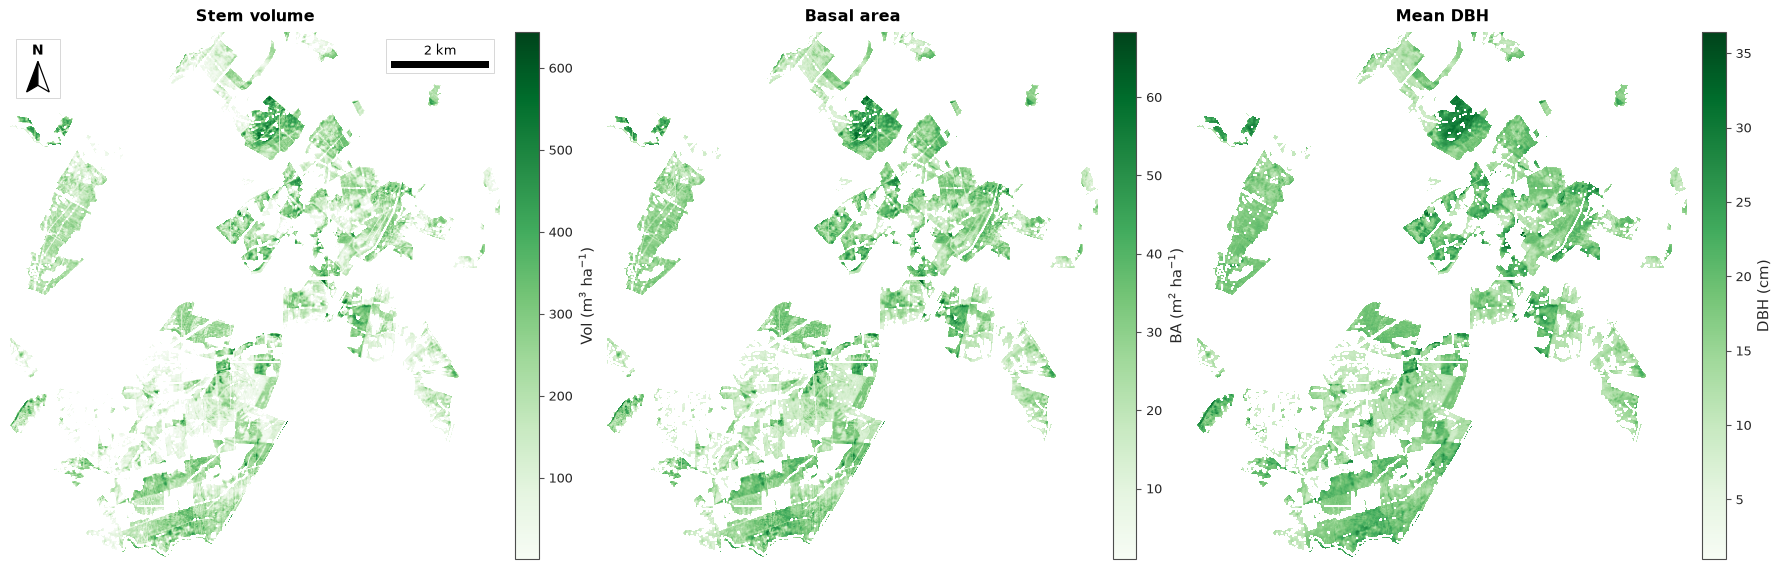

In [20]:
sub_bbox = [291171, 301190, 246680, 257452]

map_info = [
    # (image, title, colour bar label)
    (vol_out_img, "Stem volume", "Vol (m$^3$ ha$^{-1}$)"),
    (ba_out_img, "Basal area", "BA (m$^2$ ha$^{-1}$)"),
    (dbh_out_img, "Mean DBH", "DBH (cm)"),
]
panels = [
    MapPanel(
        "cmap",
        img,
        bands=1,
        title=title,
        cmap_name="Greens",
        vmin=1,
        show_colour_bar=True,
        cbar_label=label,
        map_kw={"vals_under_white": True},
    )
    for img, title, label in map_info
]
fig, axs = create_map_panels(panels, bbox=sub_bbox)